# โมเดลที่ 2 — PCA + Nearest Centroid (ข้อมูลจริง 4 คน)

ไฟล์ `features_ready_2.csv` = ข้อมูลจริงของ **it, nick, ski, tonson** × 6 กิจกรรม × 45 หน้าต่าง = 1080 แถว
- ตัดหน้าต่าง 128 / เลื่อน 64, คำนวณ 24 ฟีเจอร์, ปรับสเกล −1..1 มาแล้ว ✅
- **ทุกแถวเป็น train — ไม่มี test**

**ปัญหา:** ไม่มี test แล้วจะรู้ได้ยังไงว่าโมเดลดีแค่ไหน และจะเลือก k ยังไง?
**ทางออก:** ใช้ **validation** = แบ่งข้อมูล train บางส่วนออกมาเป็น "ข้อสอบซ้อม" ชั่วคราว ใช้วัดผลและเลือก k พอตัดสินใจได้แล้ว ค่อยเทรนโมเดลจริงจาก**ข้อมูลทั้งหมด**

```
ส่วน A: สร้างโมเดลทีละขั้น (เหมือนโมเดลจิ๋ว)  μ → C → eigen → ฉาย → centroid → predict
ส่วน B: ไม่มี test → วัดผลด้วย validation 2 แบบ แล้วเลือก k
ส่วน C: เทรนโมเดลสุดท้ายด้วยข้อมูลทั้งหมด → บันทึกส่งทีม Wi-Fi
```

## 0. Import และโหลดข้อมูล

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)

DATA_PATH = "features_ready_2.csv"      # วางไฟล์ไว้โฟลเดอร์เดียวกับ notebook
df = pd.read_csv(DATA_PATH)
print("ขนาดตาราง:", df.shape)
df.head()

ขนาดตาราง: (1080, 27)


,ax_mean,ax_std,ax_min,ax_max,ay_mean,ay_std,ay_min,ay_max,az_mean,az_std,...,gy_std,gy_min,gy_max,gz_mean,gz_std,gz_min,gz_max,subject,activity,split
0,0.042132,-0.447443,-0.142530,-0.152158,0.852624,-0.461211,0.527030,0.122031,-0.533123,-0.406746,...,-0.491351,0.454966,-0.677556,-0.335274,-0.431918,0.602657,-0.516367,it,downstairs,train
1,0.042946,-0.452599,-0.328806,-0.161308,0.877966,-0.266354,0.527030,0.356045,-0.501605,-0.407433,...,-0.456124,0.454966,-0.677556,-0.224459,-0.359119,0.602657,-0.394087,it,downstairs,train
2,0.009451,-0.314486,-0.328806,-0.046524,0.877860,-0.215293,0.499386,0.356045,-0.436135,-0.464963,...,-0.353430,0.336155,-0.318800,-0.111463,-0.218533,0.588813,-0.345324,it,downstairs,train
3,0.022992,-0.383924,-0.192709,-0.027500,0.864355,-0.190399,0.414093,0.608310,-0.545259,-0.436045,...,-0.145524,0.201075,-0.255549,-0.284924,-0.339458,0.588813,-0.345324,it,downstairs,train
4,0.033734,-0.411628,-0.249483,-0.027500,0.855292,-0.190599,0.414093,0.608310,-0.430326,-0.496534,...,-0.116680,0.201075,-0.132419,-0.285085,-0.503905,0.580787,-0.564814,it,downstairs,train


## 1. สำรวจข้อมูล

**ทำไมต้องเช็ก:** ถ้ากิจกรรมไม่ครบ มีค่าว่าง หรือไม่ได้สเกล โมเดลก็ยังรันผ่าน แต่จะทายผิดโดยไม่มีอะไรเตือนเลย

In [4]:
print("ค่าว่างทั้งตาราง:", df.isna().sum().sum())
print("ผู้ทดลอง:", list(df["subject"].unique()))
if "split" in df.columns:
    print("ค่าในคอลัมน์ split:", df["split"].value_counts().to_dict())
print()
print(pd.crosstab(df["subject"], df["activity"], margins=True))

ค่าว่างทั้งตาราง: 0
ผู้ทดลอง: ['it', 'nick', 'ski', 'tonson']
ค่าในคอลัมน์ split: {'train': 1080}

activity  downstairs  laying_left  sitting  standing  upstairs  walking   All
subject                                                                      
it                45           45       45        45        45       45   270
nick              45           45       45        45        45       45   270
ski               45           45       45        45        45       45   270
tonson            45           45       45        45        45       45   270
All              180          180      180       180       180      180  1080


In [5]:
FEATURE_COLS = [f"{ch}_{st}"
                for ch in ["ax", "ay", "az", "gx", "gy", "gz"]
                for st in ["mean", "std", "min", "max"]]
missing = [c for c in FEATURE_COLS if c not in df.columns]
assert not missing, f"ขาดคอลัมน์ {missing}"

X_all = df[FEATURE_COLS].to_numpy()          # ใช้ FEATURE_COLS เรียงคอลัมน์เสมอ (ข้อ 9 ในเอกสารประชุม)
y_all = df["activity"].to_numpy(dtype=str)
s_all = df["subject"].to_numpy(dtype=str)
print("X:", X_all.shape, "| ช่วงค่า:", X_all.min().round(3), "ถึง", X_all.max().round(3))

X: (1080, 24) | ช่วงค่า: -1.0 ถึง 1.0


---
# ส่วน A — สร้างโมเดลทีละขั้น

ส่วนนี้เขียนแบบคลี่ออกทีละบรรทัด ให้เทียบกับขั้นในโมเดลจิ๋วได้ง่าย พอเข้าใจแล้ว ส่วน B จะรวบทั้งหมดไว้ในฟังก์ชัน `fit()` เดียว

## 2. ขั้น 4.1–4.2: หา μ แล้วลบออก

In [6]:
mu = X_all.mean(axis=0)            # เฉลี่ยลงไปตามแถว → 24 ค่า
Xc = X_all - mu                    # broadcasting: ลบ mu ทุกแถว
print("μ =", mu)
print("เช็ก: ค่าเฉลี่ยหลังลบ μ ≈ 0 ไหม →", np.abs(Xc.mean(axis=0)).max())

μ = [ 0.025  -0.5319  0.0425 -0.1118  0.4468 -0.5937  0.1225 -0.1432 -0.3967
 -0.6049  0.0867 -0.6065  0.0129 -0.5114  0.5231 -0.5818 -0.1969 -0.5442
  0.571  -0.659  -0.2232 -0.4235  0.5227 -0.571 ]
เช็ก: ค่าเฉลี่ยหลังลบ μ ≈ 0 ไหม → 7.894919286223336e-17


## 3. ขั้น 4.3: Covariance matrix

`C = X̃ᵀ · X̃ ÷ (n − 1)` ช่อง (i, j) คือผลรวมของ x̃ᵢ·x̃ⱼ ทุกแถว เหมือนตอนเราคิด C₁₂ ด้วยมือ

ขนาด C:

 (24, 24) | ตรงกับ np.cov ไหม: True


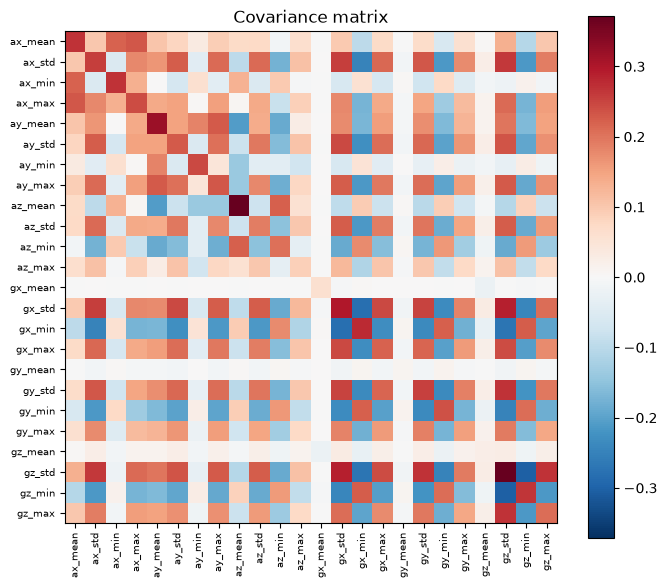

In [7]:
n = len(Xc)
Cov = Xc.T @ Xc / (n - 1)
print("ขนาด C:", Cov.shape, "| ตรงกับ np.cov ไหม:", np.allclose(Cov, np.cov(X_all, rowvar=False)))

fig, ax = plt.subplots(figsize=(7, 6))
lim = np.abs(Cov).max()
im = ax.imshow(Cov, cmap="RdBu_r", vmin=-lim, vmax=lim)
ax.set_xticks(range(24)); ax.set_xticklabels(FEATURE_COLS, rotation=90, fontsize=7)
ax.set_yticks(range(24)); ax.set_yticklabels(FEATURE_COLS, fontsize=7)
ax.set_title("Covariance matrix"); fig.colorbar(im); plt.tight_layout(); plt.show()

ช่องนอกแนวทแยงที่สีเข้มคือคู่ฟีเจอร์ที่บอกเรื่องเดียวกัน เพราะมีความซ้ำซ้อนแบบนี้ PCA ถึงยุบ 24 มิติให้เหลือน้อยลงได้

## 4. ขั้น 4.4–4.5: Eigenvalue / Eigenvector

`np.linalg.eigh` ใช้กับเมทริกซ์สมมาตร (covariance สมมาตรเสมอ) ⚠️ ฟังก์ชันนี้คืนค่าเรียงจาก**น้อยไปมาก** ต้องกลับลำดับก่อนใช้ และ eigenvector แต่ละตัวคือ**คอลัมน์** `eigvecs[:, i]` ไม่ใช่แถว

In [8]:
eigvals, eigvecs = np.linalg.eigh(Cov)
order = np.argsort(eigvals)[::-1]
eigvals, eigvecs = eigvals[order], eigvecs[:, order]

v1 = eigvecs[:, 0]
print("C·v = λ·v จริงไหม:", np.allclose(Cov @ v1, eigvals[0] * v1))
print("eigenvector ตั้งฉากกันหมดไหม:", np.allclose(eigvecs.T @ eigvecs, np.eye(24)))

explained  = eigvals / eigvals.sum()
cumulative = np.cumsum(explained)
pd.DataFrame({"eigenvalue": eigvals.round(4),
              "% ต่อทิศ": (explained * 100).round(2),
              "% สะสม": (cumulative * 100).round(2)},
             index=[f"PC{i+1}" for i in range(24)]).head(12)

C·v = λ·v จริงไหม: True
eigenvector ตั้งฉากกันหมดไหม: True


,eigenvalue,% ต่อทิศ,% สะสม
PC1,3.3522,63.48,63.48
PC2,0.7573,14.34,77.82
PC3,0.6123,11.60,89.42
PC4,0.1487,2.82,92.24
PC5,0.1188,2.25,94.48
PC6,0.0727,1.38,95.86
PC7,0.0519,0.98,96.84
PC8,0.0325,0.62,97.46
PC9,0.0254,0.48,97.94
PC10,0.0241,0.46,98.40


ถ้าใช้เกณฑ์ความกระจายสะสม ≥ 90% → k = 4


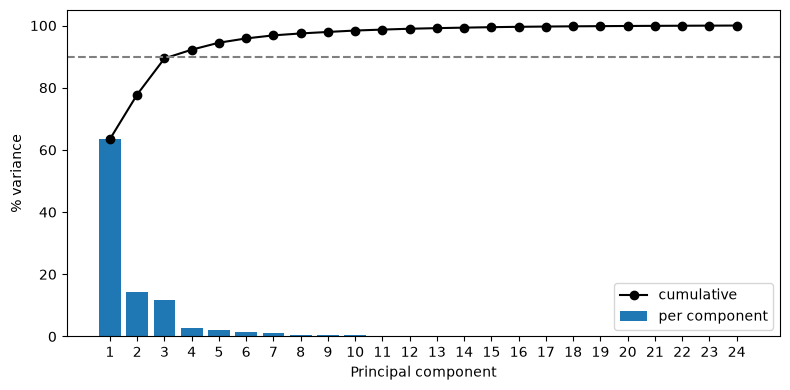

In [9]:
K_VAR90 = int(np.argmax(cumulative >= 0.90) + 1)
print(f"ถ้าใช้เกณฑ์ความกระจายสะสม ≥ 90% → k = {K_VAR90}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(range(1, 25), explained * 100, label="per component")
ax.plot(range(1, 25), cumulative * 100, "o-", color="black", label="cumulative")
ax.axhline(90, ls="--", color="gray")
ax.set_xlabel("Principal component"); ax.set_ylabel("% variance")
ax.set_xticks(range(1, 25)); ax.legend(); plt.tight_layout(); plt.show()

เกณฑ์ 90% เป็นแค่จุดเริ่มต้น จากที่เราเจอมาแล้ว ทิศที่ข้อมูลกระจายน้อยอาจเป็นทิศที่ช่วยแยกกิจกรรมก็ได้ ค่า k ตัวจริงจะเลือกในส่วน B ด้วย validation

## 5. ขั้น 4.6–4.7: ฉายลง k ทิศ แล้วหา centroid (ใช้ k จากเกณฑ์ 90% ไปก่อนเพื่อดูภาพ)

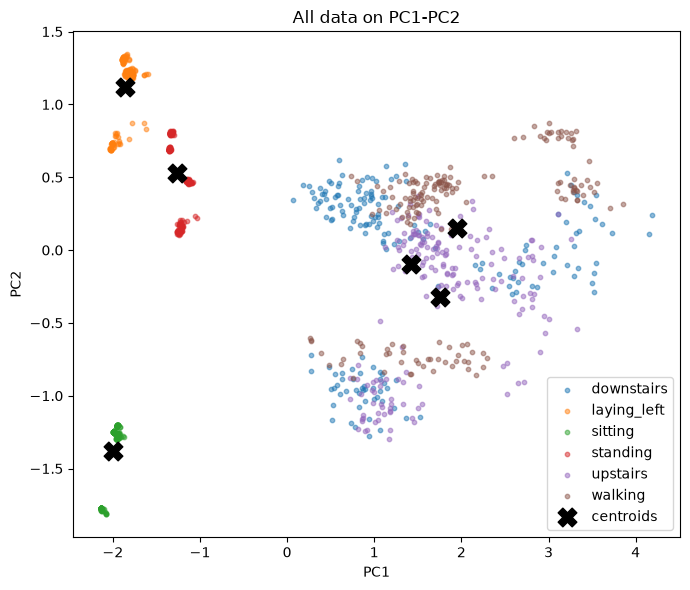

,PC1,PC2,PC3,PC4
downstairs,1.423,-0.096,-0.120,-0.204
laying_left,-1.861,1.117,0.866,0.234
sitting,-2.002,-1.381,0.503,-0.199
standing,-1.258,0.529,-1.300,-0.202
upstairs,1.753,-0.322,0.047,0.401
walking,1.946,0.152,0.003,-0.030


In [10]:
k_demo = K_VAR90
W = eigvecs[:, :k_demo]                 # (24, k)
Z = Xc @ W                              # (1080, k)
classes = np.unique(y_all)
centroids = np.array([Z[y_all == c].mean(axis=0) for c in classes])

fig, ax = plt.subplots(figsize=(7, 6))
for c in classes:
    m = y_all == c
    ax.scatter(Z[m, 0], Z[m, 1], s=10, alpha=0.5, label=c)
ax.scatter(centroids[:, 0], centroids[:, 1], s=180, marker="X", color="black", label="centroids")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_title("All data on PC1-PC2"); ax.legend()
plt.tight_layout(); plt.show()
pd.DataFrame(centroids, index=classes, columns=[f"PC{i+1}" for i in range(k_demo)]).round(3)

## 6. ขั้น 5: ฟังก์ชันทาย

ข้อมูลใหม่ต้องผ่านขั้นตอนเดียวกับตอนเทรนทุกขั้น และต้องใช้ μ, W, centroid **ชุดเดิม** แล้วเลือก centroid ที่อยู่ใกล้ที่สุด (ระยะ Euclidean ใน k มิติ)

In [11]:
def predict(X, mu, W, centroids, classes):
    Z = (np.atleast_2d(X) - mu) @ W
    dist = np.linalg.norm(Z[:, None, :] - centroids[None, :, :], axis=2)   # (n, 6)
    return classes[np.argmin(dist, axis=1)]

def fit(X, y, k):
    """รวบขั้น 4.1–4.7 ทั้งหมด: คืนโมเดล (mu, W, centroids, classes)"""
    mu = X.mean(axis=0)
    vals, vecs = np.linalg.eigh(np.cov(X, rowvar=False))
    W = vecs[:, np.argsort(vals)[::-1][:k]]
    cl = np.unique(y)
    cents = np.array([((X[y == c] - mu) @ W).mean(axis=0) for c in cl])
    return mu, W, cents, cl

resub = (predict(X_all, mu, W, centroids, classes) == y_all).mean()
print(f"ทายข้อมูลที่ใช้เทรนเอง (k = {k_demo}) ได้ {resub*100:.1f}%  ← ⚠️ ตัวเลขนี้ห้ามรายงานเป็นความแม่น! (ดูส่วน B)")

ทายข้อมูลที่ใช้เทรนเอง (k = 4) ได้ 80.7%  ← ⚠️ ตัวเลขนี้ห้ามรายงานเป็นความแม่น! (ดูส่วน B)


---
# ส่วน B — ไม่มี test แล้ววัดผลยังไง?

การเอาข้อมูลที่ใช้เทรนมาทายเองแล้วบอกว่าเป็นความแม่น ก็เหมือน**ครูเอาข้อสอบที่ใช้ติวมาออกสอบจริง** คะแนนจะสูงเกินจริงเสมอ เราต้องมีข้อมูลบางส่วนที่โมเดลไม่เคยเห็นตอนเทรน

ทำ validation 2 แบบ ซึ่งตอบคำถามคนละข้อ:

| แบบ | วิธีแบ่ง | ตอบคำถามว่า |
|---|---|---|
| **B1. Time hold-out** | แต่ละคน/กิจกรรม: 70% แรก (31 หน้าต่าง) เทรน, 30% หลัง (14) ทดสอบ | ถ้าคนเดิมใช้ต่อ จะแม่นแค่ไหน |
| **B2. Leave-one-subject-out** | เทรนด้วย 3 คน ทดสอบกับคนที่ 4 วนจนครบ | ถ้าเจอ**คนใหม่**ที่ไม่เคยเห็น จะแม่นแค่ไหน |

**ทำไมแบ่งตามเวลา ไม่สุ่ม:** หน้าต่างที่ติดกันซ้อนทับกันครึ่งหนึ่ง ถ้าสุ่มแบ่ง หน้าต่างที่ 5 อาจไปอยู่ฝั่งเทรน และหน้าต่างที่ 6 อยู่ฝั่งทดสอบ โมเดลจะเหมือนเคยเห็นข้อสอบมาแล้วครึ่งข้อ

In [12]:
pos = df.groupby(["subject", "activity"]).cumcount().to_numpy()   # ลำดับหน้าต่างภายในแต่ละคน/กิจกรรม
n_per = df.groupby(["subject", "activity"]).size().to_numpy().min()
CUT = int(round(n_per * 0.7))                                      # 45 → 31
is_tr = pos < CUT
print(f"B1: เทรน {is_tr.sum()} แถว (หน้าต่างที่ 0–{CUT-1}) | validation {(~is_tr).sum()} แถว (หน้าต่างที่ {CUT}–{n_per-1})")

def eval_k(k):
    m = fit(X_all[is_tr], y_all[is_tr], k)
    b1 = (predict(X_all[~is_tr], *m) == y_all[~is_tr]).mean()
    loso = {}
    for p in np.unique(s_all):
        m2 = fit(X_all[s_all != p], y_all[s_all != p], k)
        loso[p] = (predict(X_all[s_all == p], *m2) == y_all[s_all == p]).mean()
    return b1, loso

rows = []
for k in range(1, 25):
    b1, loso = eval_k(k)
    rows.append({"k": k, "B1 time hold-out": b1, "B2 คนใหม่ (เฉลี่ย)": np.mean(list(loso.values())),
                 **{f"B2: {p}": v for p, v in loso.items()}})
val = pd.DataFrame(rows).set_index("k")
(val * 100).round(1).head(12)

B1: เทรน 744 แถว (หน้าต่างที่ 0–30) | validation 336 แถว (หน้าต่างที่ 31–44)


,B1 time hold-out,B2 คนใหม่ (เฉลี่ย),B2: it,B2: nick,B2: ski,B2: tonson
k,,,,,,
1,65.2,60.0,56.3,68.9,67.0,47.8
2,74.1,72.5,82.6,69.3,67.8,70.4
3,75.0,76.1,85.2,67.8,68.1,83.3
4,81.2,80.5,91.9,70.4,78.5,81.1
5,82.1,81.3,92.6,81.5,78.5,72.6
6,81.5,80.8,89.3,81.5,80.7,71.9
7,87.8,83.6,93.3,81.5,81.9,77.8
8,88.1,83.3,93.7,80.0,81.9,77.8
9,88.4,83.5,93.7,80.7,81.9,77.8


## 7. เลือก k

กฎที่ใช้คือ **เลือก k ที่น้อยที่สุด ที่ความแม่นของ B1 ห่างจากค่าดีที่สุดไม่เกิน 1%**

ทำไมไม่เลือก k ที่ได้คะแนนสูงสุดไปเลย: เพราะพอ k เกินช่วงหนึ่งไปแล้ว คะแนนจะแทบไม่ขยับ ทิศที่เพิ่มเข้ามาส่วนใหญ่เป็น noise การเลือก k น้อยกว่าทำให้โมเดลเล็กกว่า คำนวณเร็วกว่า และมีโอกาสน้อยกว่าที่จะไปจำ noise ที่เกิดเฉพาะกับข้อมูลชุดนี้

B1 ดีที่สุด = 88.7%  →  เลือก k = 7  (B1 = 87.8%, คนใหม่ = 83.6%)
เทียบเกณฑ์ 90%: k = 4 → B1 = 81.2%


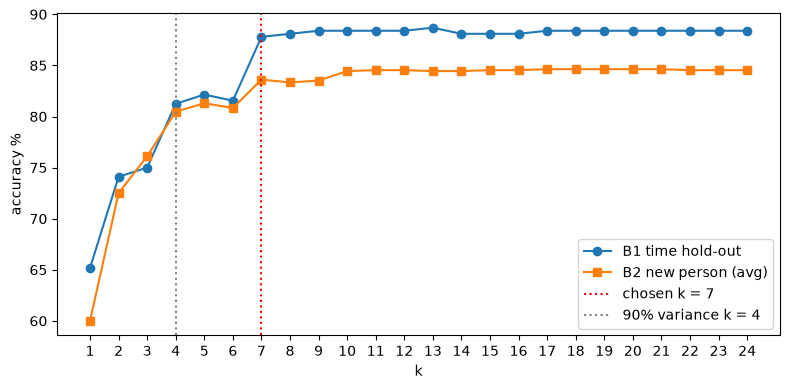

In [13]:
TOL = 0.01
best = val["B1 time hold-out"].max()
K = int(val.index[val["B1 time hold-out"] >= best - TOL].min())
# K = 7   # ← ถ้าอยากกำหนดเอง ให้เปิดบรรทัดนี้
print(f"B1 ดีที่สุด = {best*100:.1f}%  →  เลือก k = {K}  (B1 = {val.loc[K, 'B1 time hold-out']*100:.1f}%, "
      f"คนใหม่ = {val.loc[K, 'B2 คนใหม่ (เฉลี่ย)']*100:.1f}%)")
print(f"เทียบเกณฑ์ 90%: k = {K_VAR90} → B1 = {val.loc[K_VAR90, 'B1 time hold-out']*100:.1f}%")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(val.index, val["B1 time hold-out"] * 100, "o-", label="B1 time hold-out")
ax.plot(val.index, val["B2 คนใหม่ (เฉลี่ย)"] * 100, "s-", label="B2 new person (avg)")
ax.axvline(K, ls=":", color="red", label=f"chosen k = {K}")
ax.axvline(K_VAR90, ls=":", color="gray", label=f"90% variance k = {K_VAR90}")
ax.set_xlabel("k"); ax.set_ylabel("accuracy %"); ax.set_xticks(range(1, 25)); ax.legend()
plt.tight_layout(); plt.show()

## 8. ดูว่าผิดตรงไหน (ที่ k ที่เลือก)

**Confusion matrix ของ B1** แถวคือคำตอบจริง คอลัมน์คือสิ่งที่โมเดลทาย ช่องที่อยู่นอกแนวทแยงคือคู่กิจกรรมที่โมเดลสับสนกัน

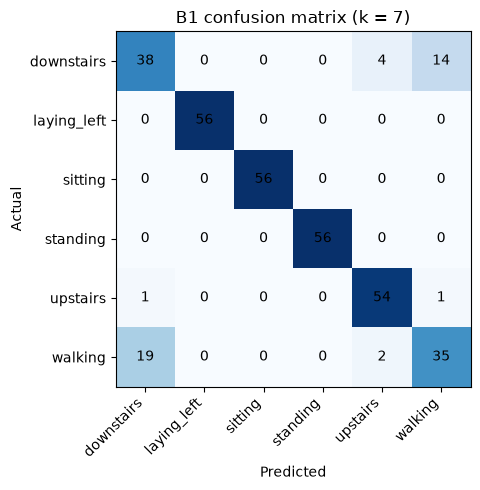

B1 แยกตามคน: {np.str_('it'): '94.0%', np.str_('nick'): '89.3%', np.str_('ski'): '85.7%', np.str_('tonson'): '82.1%'}
B2 คนใหม่  : {np.str_('it'): '93.3%', np.str_('nick'): '81.5%', np.str_('ski'): '81.9%', np.str_('tonson'): '77.8%'}


In [14]:
mB1 = fit(X_all[is_tr], y_all[is_tr], K)
pB1 = predict(X_all[~is_tr], *mB1)
cm = pd.crosstab(pd.Series(y_all[~is_tr], name="จริง"), pd.Series(pB1, name="ทาย"))
cm = cm.reindex(index=classes, columns=classes, fill_value=0)

fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(cm.values, cmap="Blues")
for i in range(len(classes)):
    for j in range(len(classes)):
        ax.text(j, i, cm.values[i, j], ha="center", va="center")
ax.set_xticks(range(6)); ax.set_xticklabels(classes, rotation=45, ha="right")
ax.set_yticks(range(6)); ax.set_yticklabels(classes)
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(f"B1 confusion matrix (k = {K})")
plt.tight_layout(); plt.show()

s_val = s_all[~is_tr]
print("B1 แยกตามคน:", {p: f"{(pB1[s_val == p] == y_all[~is_tr][s_val == p]).mean()*100:.1f}%"
                       for p in np.unique(s_val)})
print("B2 คนใหม่  :", {p: f"{val.loc[K, f'B2: {p}']*100:.1f}%" for p in np.unique(s_all)})

---
# ส่วน C — โมเดลสุดท้าย

ใช้ validation ตัดสินใจเรื่อง k ไปแล้ว ตอนนี้เอา**ข้อมูลทั้ง 1080 แถว**มาเทรน เพราะยิ่งมีข้อมูลมาก centroid ก็ยิ่งแม่น ความแม่นที่จะรายงานคือตัวเลขจากส่วน B ไม่ใช่การเอาข้อมูลที่ใช้เทรนมาทายเอง

In [15]:
mu_f, W_f, cents_f, classes_f = fit(X_all, y_all, K)
pd.DataFrame(cents_f, index=classes_f, columns=[f"PC{i+1}" for i in range(K)]).round(3)

,PC1,PC2,PC3,PC4,PC5,PC6,PC7
downstairs,1.423,-0.096,-0.120,-0.204,-0.049,-0.013,0.038
laying_left,-1.861,1.117,0.866,0.234,-0.159,-0.002,-0.013
sitting,-2.002,-1.381,0.503,-0.199,0.185,-0.000,0.031
standing,-1.258,0.529,-1.300,-0.202,-0.082,0.019,-0.024
upstairs,1.753,-0.322,0.047,0.401,0.099,0.052,-0.261
walking,1.946,0.152,0.003,-0.030,0.006,-0.056,0.229


## 9. บันทึกโมเดลส่งให้ทีม Wi-Fi

⚠️ **ยังขาด min/max 24 คู่** ที่เพื่อนใช้ปรับสเกล ค่าพวกนี้ไม่มีอยู่ใน CSV ถ้าไม่มี ทีม Wi-Fi จะสเกลข้อมูลเรียลไทม์ไม่ได้

In [16]:
SCALE_MIN = None   # TODO: ขอ min ทั้ง 24 ค่าจากเพื่อนที่ทำ features_ready_2.csv (เรียงตาม FEATURE_COLS)
SCALE_MAX = None   # TODO: ขอ max ทั้ง 24 ค่า

np.savez("model2.npz",
         feature_cols=np.array(FEATURE_COLS), k=K,
         mu=mu_f, W=W_f, centroids=cents_f, classes=classes_f,
         scale_min=np.array([]) if SCALE_MIN is None else np.array(SCALE_MIN),
         scale_max=np.array([]) if SCALE_MAX is None else np.array(SCALE_MAX))

m = np.load("model2.npz")
same = np.array_equal(predict(X_all, m["mu"], m["W"], m["centroids"], m["classes"]),
                      predict(X_all, mu_f, W_f, cents_f, classes_f))
print("บันทึก model2.npz แล้ว | โหลดกลับมาทายได้ผลเหมือนเดิม:", same)

บันทึก model2.npz แล้ว | โหลดกลับมาทายได้ผลเหมือนเดิม: True


## สรุป

| ขั้น (โมเดลจิ๋ว) | ในโค้ด |
|---|---|
| 4.1–4.2 μ, ลบ μ | `mu = X.mean(axis=0)`, `Xc = X - mu` |
| 4.3 covariance | `Xc.T @ Xc / (n-1)` |
| 4.4–4.5 eigen | `np.linalg.eigh` + เรียงจากมากไปน้อย |
| เลือก k | validation (B1) ไม่ใช่ % ความกระจายอย่างเดียว |
| 4.6–4.7 ฉาย + centroid | `Z = Xc @ W`, เฉลี่ยตามกิจกรรม |
| 5 ทาย | `predict()` |

**ความแม่นที่รายงานได้:** ใช้ B1 (กรณีคนเดิม) และ B2 (กรณีคนใหม่) ห้ามใช้ตัวเลขจากการเอาข้อมูลที่ใช้เทรนมาทายเอง

**ข้อจำกัด:** ข้อมูลมี 4 คน ผลของ B2 จึงมาจากการทดสอบแค่ 4 รอบ และค่า min/max ที่ใช้ปรับสเกลถูกคำนวณจากข้อมูลทั้ง 4 คนรวมกัน ทำให้ B2 อาจได้คะแนนสูงกว่าความจริงเล็กน้อย